Billy York


2/13/26

# Non-Personalized Recommendations

In [1]:
import polars as pl
from sklearn.model_selection import GroupShuffleSplit
from scipy.stats import linregress
import seaborn as sns
from IPython.display import display, Markdown

## Experimental Setup

In [2]:
ml_x = pl.read_ipc('movielens_25m.feather', memory_map=False)
np_x = pl.read_ipc('netflix_prize.feather', memory_map=False)
yh_x = pl.read_ipc('yahoo_r2_songs.subsample.feather', memory_map=False)
bg_x = pl.read_ipc('boardgamegeek.feather', memory_map=False).fill_null('')

In [3]:
gss = GroupShuffleSplit(n_splits=1, train_size=0.75, random_state=42)

ml_train_idx, ml_test_idx = next(gss.split(X=ml_x, groups=ml_x['user_id']))
ml_train, ml_test = ml_x[ml_train_idx], ml_x[ml_test_idx]

np_train_idx, np_test_idx = next(gss.split(X=np_x, groups=np_x['user_id']))
np_train, np_test = np_x[np_train_idx], np_x[np_test_idx]

yh_train_idx, yh_test_idx = next(gss.split(X=yh_x, groups=yh_x['user_id']))
yh_train, yh_test = yh_x[yh_train_idx], yh_x[yh_test_idx]

bg_train_idx, bg_test_idx = next(gss.split(X=bg_x, groups=bg_x['user_id']))
bg_train, bg_test = bg_x[bg_train_idx], bg_x[bg_test_idx]

## Generating Recommendations

## Average Ratings

### Movie Lens

In [4]:
ml_mean = ml_train.group_by('item_id').agg(pl.mean('rating'))

### Netflix Prize

In [5]:
np_mean = np_train.group_by('item_id').agg(pl.mean("rating"))

### Yahoo! R2 Songs

In [6]:
yh_mean = yh_train.group_by('item_id').agg(pl.mean("rating"))

### BoardGameGeek

In [7]:
bg_mean = bg_train.group_by('item_id').agg(pl.mean("rating"))

## Awareness (Number)

### Movie Lens

In [8]:
ml_aware = ml_train.group_by('item_id').agg(pl.count('rating'))

### Netflix Prize

In [9]:
np_aware = np_train.group_by('item_id').agg(pl.count('rating'))

### Yahoo! R2 Songs

In [10]:
yh_aware = yh_train.group_by('item_id').agg(pl.count('rating'))

### BoardGameGeek

In [11]:
bg_aware = bg_train.group_by('item_id').agg(pl.count('rating'))

## Popularity (Number of Positive Ratings)

### Movie Lens

In [12]:
ml_pop = ml_train.filter(pl.col('rating') >= 4.0).group_by('item_id').agg(pl.count('rating'))

### Netflix Prize

In [13]:
np_pop = np_train.filter(pl.col('rating') >= 4).group_by('item_id').agg(pl.count('rating'))

### Yahoo! R2 Songs

In [14]:
yh_pop = yh_train.filter(pl.col('rating') >= 4).group_by('item_id').agg(pl.count('rating'))

### BoardGameGeek

In [15]:
bg_pop = bg_train.filter(pl.col('rating') >= 8.0).group_by('item_id').agg(pl.count('rating'))

## Evaluating Recommendations

## Average Rating

### Movie Lens

[Text(0.5, 1.0, 'MovieLens Average Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

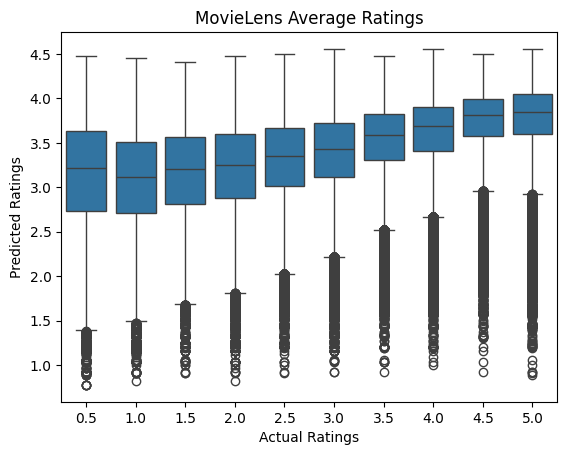

In [16]:
ml_mean_y = ml_test.join(ml_mean, on='item_id', how='inner')
ml_mean_slope, ml_mean_int, ml_mean_r, ml_mean_p, ml_mean_stderr = linregress(x=ml_mean_y['rating_right'], y=ml_mean_y['rating'])
ml_mean_rsq = ml_mean_r ** 2
sns.boxplot(x=ml_mean_y['rating'], y=ml_mean_y['rating_right']).set(title="MovieLens Average Ratings", xlabel="Actual Ratings", ylabel="Predicted Ratings")

### Netflix Prize

[Text(0.5, 1.0, 'Netflix Prize Average Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

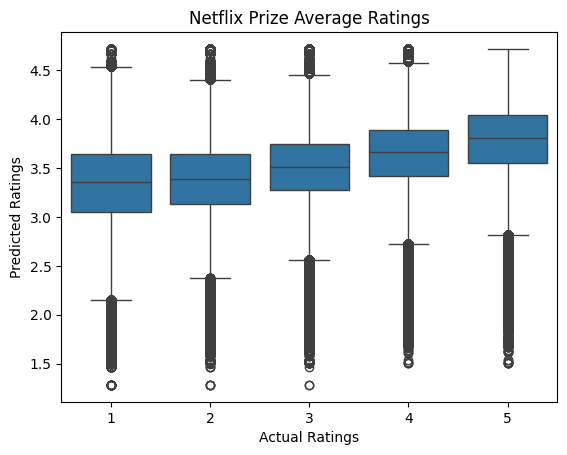

In [17]:
np_mean_y = np_test.join(np_mean, on='item_id', how='inner')
np_mean_slope, np_mean_int, np_mean_r, np_mean_p, np_mean_stderr = linregress(x=np_mean_y['rating_right'], y=np_mean_y['rating'])
np_mean_rsq = np_mean_r ** 2
sns.boxplot(x=np_mean_y['rating'], y=np_mean_y['rating_right']).set(title='Netflix Prize Average Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### Yahoo! R2 Songs

[Text(0.5, 1.0, 'Yahoo! R2 Songs Average Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

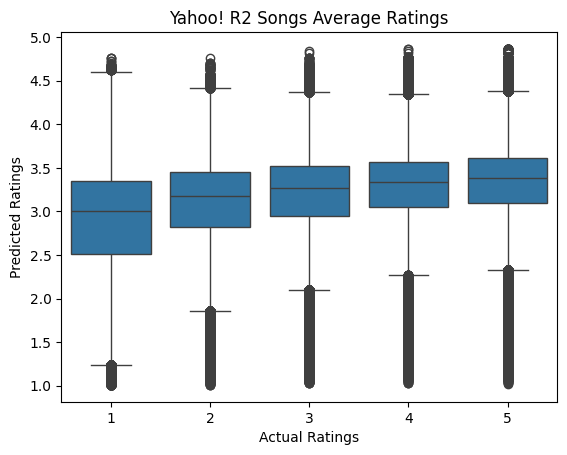

In [18]:
yh_mean_y = yh_test.join(yh_mean, on='item_id', how='inner')
yh_mean_slope, yh_mean_int, yh_mean_r, yh_mean_p, yh_mean_stderr = linregress(x=yh_mean_y['rating_right'], y=yh_mean_y['rating'])
yh_mean_rsq = yh_mean_r ** 2
sns.boxplot(x=yh_mean_y['rating'], y=yh_mean_y['rating_right']).set(title='Yahoo! R2 Songs Average Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### BoardGameGeek

In [19]:
bg_mean_y = bg_test.join(bg_mean, on='item_id', how='inner')
bg_mean_slope, bg_mean_int, bg_mean_r, bg_mean_p, bg_mean_stderr = linregress(x=bg_mean_y['rating_right'], y=bg_mean_y['rating'])
bg_mean_rsq = bg_mean_r ** 2

## Awareness

### MovieLens

[Text(0.5, 1.0, 'MovieLens Awareness Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

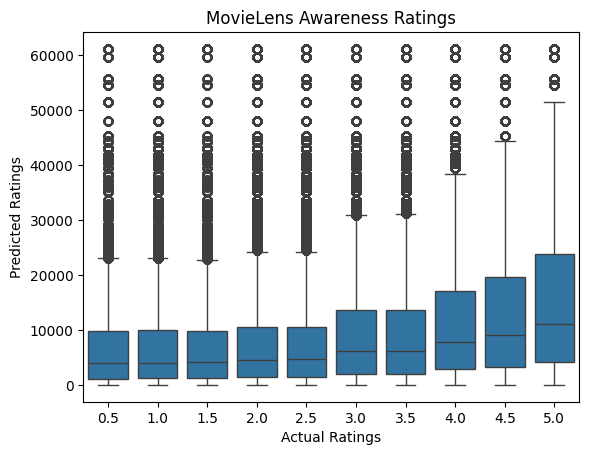

In [20]:
ml_aware_y = ml_test.join(ml_aware, on='item_id', how='inner')
ml_aware_slope, ml_aware_int, ml_aware_r, ml_aware_p, ml_aware_stderr = linregress(x=ml_aware_y['rating_right'], y=ml_aware_y['rating'])
ml_aware_rsq = ml_aware_r ** 2
sns.boxplot(x=ml_aware_y['rating'], y=ml_aware_y['rating_right']).set(title='MovieLens Awareness Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### Netflix Prize

[Text(0.5, 1.0, 'Netflix Prize Awareness Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

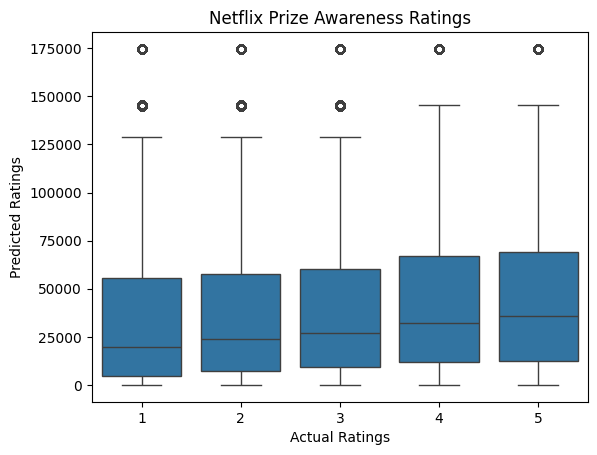

In [21]:
np_aware_y = np_test.join(np_aware, on='item_id', how='inner')
np_aware_slope, np_aware_int, np_aware_r, np_aware_p, np_aware_stderr = linregress(x=np_aware_y['rating_right'], y=np_aware_y['rating'])
np_aware_rsq = np_aware_r ** 2
sns.boxplot(x=np_aware_y['rating'], y=np_aware_y['rating_right']).set(title='Netflix Prize Awareness Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### Yahoo! R2 Songs

[Text(0.5, 1.0, 'Yahoo! R2 Songs Awareness Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

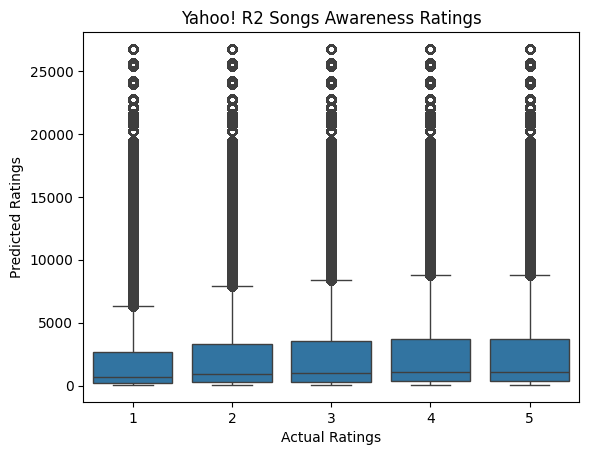

In [22]:
yh_aware_y = yh_test.join(yh_aware, on='item_id', how='inner')
yh_aware_slope, yh_aware_int, yh_aware_r, yh_aware_p, yh_aware_stderr = linregress(x=yh_aware_y['rating_right'], y=yh_aware_y['rating'])
yh_aware_rsq = yh_aware_r ** 2
sns.boxplot(x=yh_aware_y['rating'], y=yh_aware_y['rating_right']).set(title='Yahoo! R2 Songs Awareness Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### BoardGameGeek

In [23]:
bg_aware_y = bg_test.join(bg_aware, on='item_id', how='inner')
bg_aware_slope, bg_aware_int, bg_aware_r, bg_aware_p, bg_aware_stderr = linregress(x=bg_aware_y['rating_right'], y=bg_aware_y['rating'])
bg_aware_rsq = bg_aware_r ** 2

## Popularity

### MovieLens

[Text(0.5, 1.0, 'MovieLens Popularity Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

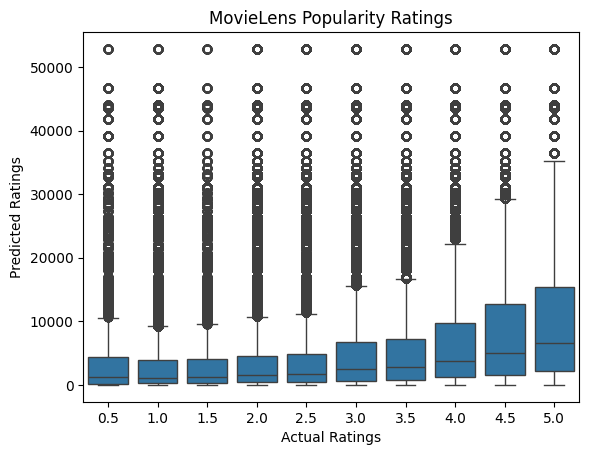

In [24]:
ml_pop_y = ml_test.join(ml_pop, on='item_id', how='inner')
ml_pop_slope, ml_pop_int, ml_pop_r, ml_pop_p, ml_pop_stderr = linregress(x=ml_pop_y['rating_right'], y=ml_pop_y['rating'])
ml_pop_rsq = ml_pop_r ** 2
sns.boxplot(x=ml_pop_y['rating'], y=ml_pop_y['rating_right']).set(title='MovieLens Popularity Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### Netflix Prize

[Text(0.5, 1.0, 'Netflix Prize Popularity Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

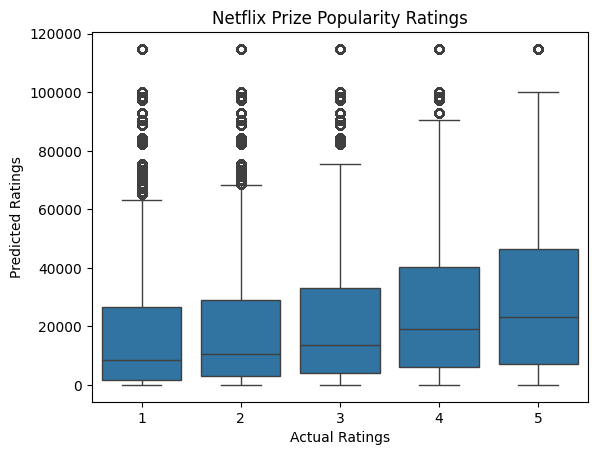

In [25]:
np_pop_y = np_test.join(np_pop, on='item_id', how='inner')
np_pop_slope, np_pop_int, np_pop_r, np_pop_p, np_pop_stderr = linregress(x=np_pop_y['rating_right'], y=np_pop_y['rating'])
np_pop_rsq = np_pop_r ** 2
sns.boxplot(x=np_pop_y['rating'], y=np_pop_y['rating_right']).set(title='Netflix Prize Popularity Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### Yahoo! R2 Songs

[Text(0.5, 1.0, 'Yahoo! R2 Songs Popularity Ratings'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

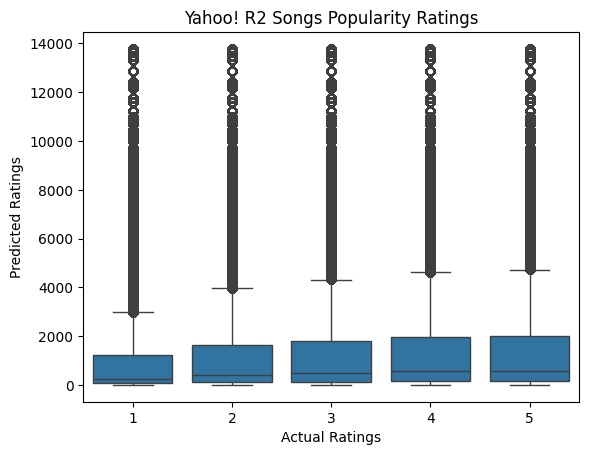

In [26]:
yh_pop_y = yh_test.join(yh_pop, on='item_id', how='inner')
yh_pop_slope, yh_pop_int, yh_pop_r, yh_pop_p, yh_pop_stderr = linregress(x=yh_pop_y['rating_right'], y=yh_pop_y['rating'])
yh_pop_rsq = yh_pop_r ** 2
sns.boxplot(x=yh_pop_y['rating'], y=yh_pop_y['rating_right']).set(title='Yahoo! R2 Songs Popularity Ratings', xlabel='Actual Ratings', ylabel='Predicted Ratings')

### BoardGameGeek

In [27]:
bg_pop_y = bg_test.join(bg_pop, on='item_id', how='inner')
bg_pop_slope, bg_pop_int, bg_pop_r, bg_pop_p, bg_pop_stderr = linregress(x=bg_pop_y['rating_right'], y=bg_pop_y['rating'])
bg_pop_rsq = bg_pop_r ** 2

## R^2 Comparison Table

In [28]:
display(Markdown(f'| Data Set | Average Rating | Awareness | Popularity |\n| - | - | - | - |\n| MovieLens | {ml_mean_rsq} | {ml_aware_rsq} | {ml_pop_rsq} |\n| Netflix Prize | {np_mean_rsq} | {np_aware_rsq} | {np_pop_rsq} |\n| Yahoo! R2 Songs | {yh_mean_rsq} | {yh_aware_rsq} | {yh_pop_rsq} |\n| BoardGameGeek | {bg_mean_rsq} | {bg_aware_rsq} | {bg_pop_rsq} |'))

| Data Set | Average Rating | Awareness | Popularity |
| - | - | - | - |
| MovieLens | 0.18085748099867413 | 0.039160596201471914 | 0.05561635040252479 |
| Netflix Prize | 0.13133428929603366 | 0.009141323349393961 | 0.02737204813316442 |
| Yahoo! R2 Songs | 0.10732176782122413 | 0.003143415233079163 | 0.006986684073556392 |
| BoardGameGeek | 0.260174766155426 | 0.03636134941612544 | 0.06358048684599614 |